# Completion steps: analysis of the released dataset

This notebook analyses completion steps using only the tables in `data/`. It produces:

| Output | Content |
|---|---|
| Table I | Completion steps per scenario: mean, SD, % completed |
| Fig. 5 | Violin plot of completion steps per scenario |
| Table II | Paired t-tests, Scenarios 1-3 |
| Table III | Paired t-tests, Scenario 4 against 1-3 and Scenarios 4-6 |
| Table IV | Frequency of alignment with recommended decisions |
| Fig. 6 | Violin plot of R and NR groups in Scenarios 4-6 |
| Table V | Welch t-tests across scenarios, within the R group and within the NR group |
| Table VI | Welch t-tests of R vs NR within each scenario |

**Data.** 267 sessions from 47 participants. Section 1 checks that the scenario tables match `data/sessions.csv`.

**Definitions.**
- **Completion steps:** the number of steps on which at least one task was unfinished. A team that never finishes scores 20, the session length.
- **Completed:** every task reached level 0 within the 20 steps.
- **Aligned decision:** a step where the human's action was among the three highest of the human agent's Q-values (10 tasks plus idle).
- **R group (Scenarios 4-6):** at least 8 aligned decisions over the 20 steps. Everyone else is NR.

Outputs go to `completion_steps_outputs/` next to this notebook.

## 1. Load the data and validate it

In [1]:
from pathlib import Path
import sys, itertools, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

ROOT = Path.cwd()
assert (ROOT / "data" / "sessions.csv").is_file(), "Run this notebook from the repository root"
sys.path.insert(0, str(ROOT / "code"))
from load_data import load_scenario

OUT_DIR = ROOT / "completion_steps_outputs"
OUT_DIR.mkdir(exist_ok=True)

SCENARIOS = [1, 2, 3, 4, 5, 6]
STEPS = 20
REC_THRESHOLD = 8   # R group: at least 8 aligned decisions
TASK_COLS = [f"task_{k}" for k in range(10)]
Q_COLS = [f"q_task_{k}" for k in range(10)] + ["q_idle"]   # action code c maps to column c - 1
NAMES = {1: "1 (LC)", 2: "2 (MC)", 3: "3 (AUI)", 4: "4 (S-AUI)", 5: "5 (S-AUI-U)", 6: "6 (S-AUI-D)"}
sns.set_theme(style="white")
pd.set_option("display.width", 200, "display.max_columns", 40)

def top3(values):
    # Indices of the three largest values; ties keep the lower index, as in the original analysis.
    return sorted(range(len(values)), key=lambda i: values[i], reverse=True)[:3]

records = []
for s in SCENARIOS:
    t = load_scenario(s)
    q_h = t["q_values"].query("agent == 'H'")[["participant_id", "step"] + Q_COLS]
    m = (t["states"].merge(t["actions"][["participant_id", "step", "H"]], on=["participant_id", "step"])
                    .merge(q_h, on=["participant_id", "step"]).sort_values(["participant_id", "step"]))
    m["active"] = m[TASK_COLS].sum(axis=1) != 0
    m["aligned"] = [int(a) - 1 in top3(q) for a, q in zip(m["H"], m[Q_COLS].to_numpy())]
    for pid, g in m.groupby("participant_id"):
        assert len(g) == STEPS and (g.step.to_numpy() == np.arange(STEPS)).all(), f"P{pid} S{s}: steps 0-19 expected"
        records.append({"participant": int(pid), "scenario": s,
                        "steps": int(g.active.sum()), "completed": bool(g.done.eq(1).any()),
                        "rec_count": int(g.aligned.sum())})
data = pd.DataFrame(records)

# Checks against the release's own index files
sessions = pd.read_csv(ROOT / "data" / "sessions.csv")
inc = sessions.rename(columns={"participant_id": "participant", "scenario_id": "scenario"})
chk = inc.merge(data, on=["participant", "scenario"], how="outer", indicator=True)
assert (chk._merge == "both").all(), "Scenario tables and sessions.csv list different sessions"
assert (chk.n_active_steps == chk.steps).all(), "Steps differ from n_active_steps in sessions.csv"
assert ((data.steps == STEPS) == ~data.completed).all(), "20 steps should mean exactly 'did not finish'"
assert len(data) == 267 and data.participant.nunique() == 47

wide = data.pivot(index="participant", columns="scenario", values="steps").reindex(columns=SCENARIOS)
print(f"{len(data)} sessions from {data.participant.nunique()} participants; "
      f"{int(wide.notna().all(axis=1).sum())} participants have all six scenarios")
display(data.groupby("scenario").size().rename("sessions").to_frame().T)
data.to_csv(OUT_DIR / "completion_steps_sessions.csv", index=False)

267 sessions from 47 participants; 37 participants have all six scenarios


scenario,1,2,3,4,5,6
sessions,44,41,47,45,47,43


### Formatting for the paper tables

Each results section shows the full table first, then a paper-style version.

- **p-values:** below 0.01 shows as `< 0.01`; below 0.1 to two decimals; otherwise one decimal.
- **Other numbers:** one decimal.
- **Effect sizes:** keep their sign, so a negative effect means the first scenario or group took fewer steps.

In [2]:
def fmt_p(p):
    return "< 0.01" if p < 0.01 else (f"{p:.2f}" if p < 0.1 else f"{p:.1f}")

def paper_table(df, label, effect):
    return pd.DataFrame({label: df.comparison, "t Statistic": df.t.map("{:.1f}".format),
                         "p value (Holm)": df.p_holm.map(fmt_p), "Effect Size": df[effect].map("{:.1f}".format),
                         "Confidence Intervals": [f"[{lo:.1f}, {hi:.1f}]" for lo, hi in zip(df.ci_low, df.ci_high)]})

def show(df):
    display(df.style.hide(axis="index"))

## 2. Table I: completion steps across scenarios

`pct_completed` is the share of sessions in which every task was finished within 20 steps. SDs are sample SDs.

In [3]:
def describe(df):
    g = df.groupby("scenario")
    return pd.DataFrame({"n": g.steps.size(), "mean": g.steps.mean(), "sd": g.steps.std(ddof=1),
                         "median": g.steps.median(), "pct_completed": 100 * g.completed.mean()})

desc = describe(data)

desc.round(1).to_csv(OUT_DIR / "table1_completion_steps.csv")

show(pd.DataFrame({"Scenario": [NAMES[s] for s in SCENARIOS], "Mean": desc["mean"].map("{:.1f}".format).values,
                   "Std. dev.": desc["sd"].map("{:.1f}".format).values,
                   "% Completion": desc["pct_completed"].map(lambda v: f"{v:.1f}%".replace(".0%", "%")).values}))

Scenario,Mean,Std. dev.,% Completion
1 (LC),15.7,2.7,84.1%
2 (MC),16.5,2.8,78%
3 (AUI),15.3,3.0,80.9%
4 (S-AUI),13.0,2.1,95.6%
5 (S-AUI-U),15.5,2.1,89.4%
6 (S-AUI-D),13.6,1.6,100%


## 3. Fig. 5: completion steps per scenario

Each violin shows the distribution. The inner box marks the interquartile range, and the white line marks the median.

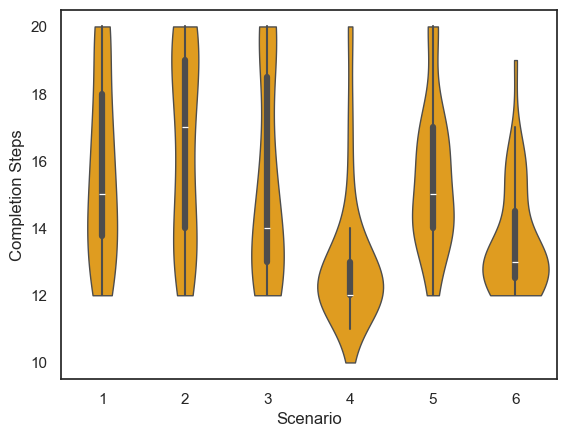

In [4]:
ax = sns.violinplot(x="scenario", y="steps", data=data, cut=0, linewidth=1, color="orange")
ax.set_xlabel("Scenario")
ax.set_ylabel("Completion Steps")

plt.savefig(OUT_DIR / "fig5_completion_steps.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Tables II and III: paired t-tests across scenarios

The same people played every scenario, so scenarios are compared with paired t-tests. Each pair uses the participants who have both sessions, matched by participant ID.

- **Holm correction:** applied across all 15 pairs, then the Table II and Table III rows are selected.
- **Effect size:** d_z, the mean of the paired differences divided by their SD.
- **Confidence interval:** the 95% CI of the mean difference, first scenario minus second.

In [5]:
rows = []
for a, b in itertools.combinations(SCENARIOS, 2):
    sub = wide[[a, b]].dropna(); x, y = sub[a].to_numpy(float), sub[b].to_numpy(float)
    res = stats.ttest_rel(x, y); ci = res.confidence_interval(0.95); diff = x - y
    rows.append({"a": a, "b": b, "comparison": f"{NAMES[a]} vs. {NAMES[b]}", "n": len(sub),
                 "mean_diff": diff.mean(), "ci_low": ci.low, "ci_high": ci.high,
                 "t": res.statistic, "df": int(res.df), "p": res.pvalue, "d_z": diff.mean() / diff.std(ddof=1)})
paired = pd.DataFrame(rows)
paired["p_holm"] = multipletests(paired.p, method="holm")[1]
paired["significant"] = paired.p_holm < 0.05
print("All 15 pairs, Holm-corrected across 15")
display(paired.drop(columns=["a", "b"]).round(3))
paired.drop(columns=["a", "b"]).round(4).to_csv(OUT_DIR / "paired_ttests_all_pairs.csv", index=False)

pick = lambda keys: paired.set_index(["a", "b"]).loc[keys].reset_index()
table2 = pick([(1, 2), (1, 3), (2, 3)])
table3 = pick([(1, 4), (2, 4), (3, 4), (4, 5), (4, 6), (5, 6)])
print("Table II: Scenarios 1-3"); show(paper_table(table2, "Scenario", "d_z"))
print("Table III: Scenarios 4-6 and against 1-3"); show(paper_table(table3, "Scenario", "d_z"))
paper_table(table2, "Scenario", "d_z").to_csv(OUT_DIR / "table2_paired_s1_s3.csv", index=False)
paper_table(table3, "Scenario", "d_z").to_csv(OUT_DIR / "table3_paired_s4_s6.csv", index=False)

All 15 pairs, Holm-corrected across 15


,comparison,n,mean_diff,ci_low,ci_high,t,df,p,d_z,p_holm,significant
0,1 (LC) vs. 2 (MC),41,-0.683,-1.867,0.501,-1.166,40,0.251,-0.182,1.000,False
1,1 (LC) vs. 3 (AUI),44,0.205,-0.782,1.192,0.418,43,0.678,0.063,1.000,False
2,1 (LC) vs. 4 (S-AUI),42,2.643,1.613,3.673,5.184,41,0.000,0.800,0.000,True
3,1 (LC) vs. 5 (S-AUI-U),44,0.114,-0.690,0.917,0.285,43,0.777,0.043,1.000,False
4,1 (LC) vs. 6 (S-AUI-D),40,1.975,0.978,2.972,4.007,39,0.000,0.634,0.002,True
5,2 (MC) vs. 3 (AUI),41,0.780,-0.178,1.739,1.645,40,0.108,0.257,0.754,False
6,2 (MC) vs. 4 (S-AUI),40,3.325,2.168,4.482,5.811,39,0.000,0.919,0.000,True
7,2 (MC) vs. 5 (S-AUI-U),41,0.805,-0.357,1.967,1.400,40,0.169,0.219,0.922,False
8,2 (MC) vs. 6 (S-AUI-D),38,2.921,1.987,3.855,6.337,37,0.000,1.028,0.000,True
9,3 (AUI) vs. 4 (S-AUI),45,2.444,1.353,3.536,4.512,44,0.000,0.673,0.000,True


Table II: Scenarios 1-3


Scenario,t Statistic,p value (Holm),Effect Size,Confidence Intervals
1 (LC) vs. 2 (MC),-1.2,1.0,-0.2,"[-1.9, 0.5]"
1 (LC) vs. 3 (AUI),0.4,1.0,0.1,"[-0.8, 1.2]"
2 (MC) vs. 3 (AUI),1.6,0.8,0.3,"[-0.2, 1.7]"


Table III: Scenarios 4-6 and against 1-3


Scenario,t Statistic,p value (Holm),Effect Size,Confidence Intervals
1 (LC) vs. 4 (S-AUI),5.2,< 0.01,0.8,"[1.6, 3.7]"
2 (MC) vs. 4 (S-AUI),5.8,< 0.01,0.9,"[2.2, 4.5]"
3 (AUI) vs. 4 (S-AUI),4.5,< 0.01,0.7,"[1.4, 3.5]"
4 (S-AUI) vs. 5 (S-AUI-U),-6.3,< 0.01,-0.9,"[-3.3, -1.7]"
4 (S-AUI) vs. 6 (S-AUI-D),-1.5,0.9,-0.2,"[-1.3, 0.2]"
5 (S-AUI-U) vs. 6 (S-AUI-D),4.9,< 0.01,0.7,"[1.1, 2.8]"


## 5. Table IV: frequency of alignment with recommended decisions

An aligned decision is a step where the human's action was among the human agent's top three options. This is the same count that forms the R and NR groups.

- **`mean` and `sd`** count all 20 logged steps, as in the original Table IV.
- **R group means are high by construction,** because R requires at least 8 aligned decisions.

In [6]:
sub456 = data[data.scenario.isin([4, 5, 6])].copy()
sub456["group"] = np.where(sub456.rec_count >= REC_THRESHOLD, "R", "NR")

def alignment_table(df):
    g = df.groupby("scenario")
    return pd.DataFrame({"n": g.size(), "mean": g.rec_count.mean(), "sd": g.rec_count.std(ddof=1)})

table4 = pd.concat({"All sessions": alignment_table(sub456),
                    "R group": alignment_table(sub456[sub456.group == "R"]),
                    "NR group": alignment_table(sub456[sub456.group == "NR"])}, names=["sessions", "scenario"])
table4 = table4.rename(index=NAMES, level="scenario")
display(table4.round(1))
table4.round(1).to_csv(OUT_DIR / "table4_alignment_with_recommendations.csv")

t4 = table4.loc["All sessions"]
print("Table IV (all sessions)")
show(pd.DataFrame({"Scenario": t4.index, "Mean": t4["mean"].map("{:.1f}".format).values, "Std. Dev": t4["sd"].map("{:.1f}".format).values}))

n  mean   sd
sessions     scenario                  
All sessions 4 (S-AUI)    45   7.8  3.7
             5 (S-AUI-U)  47   8.6  3.6
             6 (S-AUI-D)  43   6.9  2.6
R group      4 (S-AUI)    25  10.4  2.5
             5 (S-AUI-U)  26  11.2  2.5
             6 (S-AUI-D)  16   9.6  1.6
NR group     4 (S-AUI)    20   4.6  1.8
             5 (S-AUI-U)  21   5.4  1.8
             6 (S-AUI-D)  27   5.3  1.6

Table IV (all sessions)


Scenario,Mean,Std. Dev
4 (S-AUI),7.8,3.7
5 (S-AUI-U),8.6,3.6
6 (S-AUI-D),6.9,2.6


## 6. Fig. 6: R and NR groups in Scenarios 4-6

R means Recommended, at least 8 aligned decisions. NR means Not Recommended.

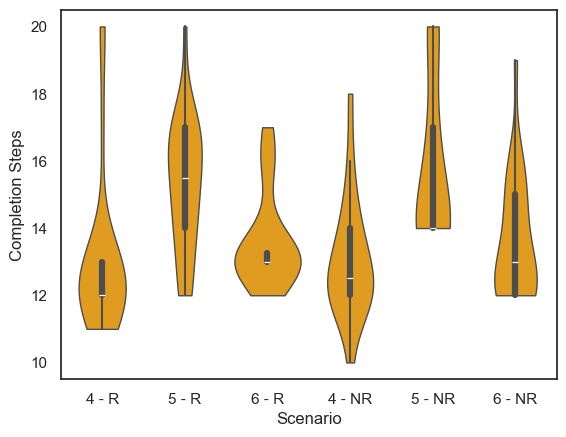

n  mean   sd
scenario group               
4        R      25  13.0  2.4
         NR     20  13.0  1.8
5        R      26  15.3  2.0
         NR     21  15.8  2.4
6        R      16  13.6  1.4
         NR     27  13.6  1.8

In [ ]:
order = ["4 - R", "5 - R", "6 - R", "4 - NR", "5 - NR", "6 - NR"]
plot_df = sub456.assign(label=lambda d: d.scenario.astype(str) + " - " + d.group)

ax = sns.violinplot(x="label", y="steps", data=plot_df, order=order,
                    cut=0, linewidth=1, color="orange")
ax.set_xlabel("Scenario")
ax.set_ylabel("Completion Steps")

plt.savefig(OUT_DIR / "fig6_r_nr_groups.png", dpi=300, bbox_inches="tight")
plt.show()

group_desc = (sub456.groupby(["scenario", "group"]).steps
              .agg(n="size", mean="mean", sd="std")
              .reindex(["R", "NR"], level=1))
display(group_desc.round(1))
group_desc.round(1).to_csv(OUT_DIR / "r_nr_group_descriptives.csv")

## 7. Table V: Welch t-tests across scenarios within each group

These tests compare completion steps between scenarios, separately for the R group and the NR group.

- **Test:** Welch's t-test, which does not assume equal variances.
- **Holm correction:** within each family of three comparisons.
- **Effect size:** Hedges' g, which is Cohen's d (pooled SD) multiplied by the small-sample correction 1 − 3 / (4(n₁ + n₂) − 9). The full tables also show d.
- **Confidence interval:** the 95% CI of the difference, first scenario minus second.

**Caveat.** Many people are in the same group in two scenarios, so the two samples overlap partly. Welch's test treats them as independent, as in the original analysis.

In [ ]:
def grp(s, g):
    return sub456[(sub456.scenario == s) & (sub456.group == g)].steps.to_numpy(float)

def welch(a, b, label):
    res = stats.ttest_ind(a, b, equal_var=False); ci = res.confidence_interval(0.95); n1, n2 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    d = (a.mean() - b.mean()) / sp
    return {"comparison": label, "n1": n1, "n2": n2, "mean1": a.mean(), "mean2": b.mean(), "mean_diff": a.mean() - b.mean(),
            "ci_low": ci.low, "ci_high": ci.high, "t": res.statistic, "df": res.df, "p": res.pvalue, "d": d, "g": d * (1 - 3 / (4 * (n1 + n2) - 9))}

def family(rows):
    df = pd.DataFrame(rows); df["p_holm"] = multipletests(df.p, method="holm")[1]; df["significant"] = df.p_holm < 0.05
    return df

pairs456 = [(4, 5), (4, 6), (5, 6)]
across_R = family([welch(grp(a, "R"), grp(b, "R"), f"{NAMES[a]} vs. {NAMES[b]}") for a, b in pairs456])
across_NR = family([welch(grp(a, "NR"), grp(b, "NR"), f"{NAMES[a]} vs. {NAMES[b]}") for a, b in pairs456])
print("R group"); display(across_R.round(3))
print("NR group"); display(across_NR.round(3))
pd.concat([across_R.assign(group="R"), across_NR.assign(group="NR")]).round(4).to_csv(OUT_DIR / "table5_welch_across_scenarios.csv", index=False)

print("Table V: Recommended Decisions (R)"); show(paper_table(across_R, "Recommended Decisions (R)", "g"))
print("Table V: Not Recommended (NR) Decisions"); show(paper_table(across_NR, "Not Recommended (NR) Decisions", "g"))

R group


,comparison,n1,n2,mean1,mean2,mean_diff,ci_low,ci_high,t,df,p,d,g,p_holm,significant
0,4 (S-AUI) vs. 5 (S-AUI-U),25,26,13.040,15.269,-2.229,-3.450,-1.009,-3.675,46.638,0.001,-1.033,-1.017,0.002,True
1,4 (S-AUI) vs. 6 (S-AUI-D),25,16,13.040,13.625,-0.585,-1.774,0.604,-0.995,38.890,0.326,-0.286,-0.281,0.326,False
2,5 (S-AUI-U) vs. 6 (S-AUI-D),26,16,15.269,13.625,1.644,0.593,2.696,3.163,38.841,0.003,0.931,0.913,0.006,True


NR group


,comparison,n1,n2,mean1,mean2,mean_diff,ci_low,ci_high,t,df,p,d,g,p_holm,significant
0,4 (S-AUI) vs. 5 (S-AUI-U),20,21,13.05,15.810,-2.760,-4.080,-1.439,-4.234,36.809,0.000,-1.313,-1.288,0.000,True
1,4 (S-AUI) vs. 6 (S-AUI-D),20,27,13.05,13.593,-0.543,-1.597,0.512,-1.039,41.352,0.305,-0.306,-0.301,0.305,False
2,5 (S-AUI-U) vs. 6 (S-AUI-D),21,27,15.81,13.593,2.217,0.955,3.479,3.563,35.980,0.001,1.075,1.057,0.002,True


Table V: Recommended Decisions (R)


Recommended Decisions (R),t Statistic,p value (Holm),Effect Size,Confidence Intervals
4 (S-AUI) vs. 5 (S-AUI-U),-3.7,< 0.01,-1.0,"[-3.4, -1.0]"
4 (S-AUI) vs. 6 (S-AUI-D),-1.0,0.3,-0.3,"[-1.8, 0.6]"
5 (S-AUI-U) vs. 6 (S-AUI-D),3.2,< 0.01,0.9,"[0.6, 2.7]"


Table V: Not Recommended (NR) Decisions


Not Recommended (NR) Decisions,t Statistic,p value (Holm),Effect Size,Confidence Intervals
4 (S-AUI) vs. 5 (S-AUI-U),-4.2,< 0.01,-1.3,"[-4.1, -1.4]"
4 (S-AUI) vs. 6 (S-AUI-D),-1.0,0.3,-0.3,"[-1.6, 0.5]"
5 (S-AUI-U) vs. 6 (S-AUI-D),3.6,< 0.01,1.1,"[1.0, 3.5]"


## 8. Table VI: R vs NR within each scenario

These tests compare completion steps between the R and NR groups in the same scenario. The two groups are different people, so Welch's t-test is the natural choice.

- **Holm correction:** across the three scenarios.
- **Effect size and CI:** Hedges' g and the 95% CI, as in Table V, with R minus NR.

In [ ]:
within = family([welch(grp(s, "R"), grp(s, "NR"), NAMES[s]) for s in (4, 5, 6)])
display(within.round(3))
within.round(4).to_csv(OUT_DIR / "table6_r_vs_nr_within_scenario.csv", index=False)
print("Table VI: R vs. NR within each scenario"); show(paper_table(within, "Scenario (R vs. NR)", "g"))

,comparison,n1,n2,mean1,mean2,mean_diff,ci_low,ci_high,t,df,p,d,g,p_holm,significant
0,4 (S-AUI),25,20,13.040,13.050,-0.010,-1.248,1.228,-0.016,42.843,0.987,-0.005,-0.005,1.0,False
1,5 (S-AUI-U),26,21,15.269,15.810,-0.540,-1.845,0.765,-0.838,38.523,0.407,-0.251,-0.247,1.0,False
2,6 (S-AUI-D),16,27,13.625,13.593,0.032,-0.963,1.028,0.066,37.488,0.948,0.020,0.019,1.0,False


Table VI: R vs. NR within each scenario


Scenario (R vs. NR),t Statistic,p value (Holm),Effect Size,Confidence Intervals
4 (S-AUI),-0.0,1.0,-0.0,"[-1.2, 1.2]"
5 (S-AUI-U),-0.8,1.0,-0.2,"[-1.8, 0.8]"
6 (S-AUI-D),0.1,1.0,0.0,"[-1.0, 1.0]"


## 9. Summary

In [ ]:
sig = lambda df: ", ".join(df.loc[df.significant, "comparison"]) or "none"
display(Markdown(f'''
- **Data:** {len(data)} sessions from {data.participant.nunique()} participants. The tables match `sessions.csv`.
- **Table I:** mean completion steps range from {desc['mean'].min():.1f} to {desc['mean'].max():.1f}. Scenario 6 has the highest completion rate ({desc.loc[6, 'pct_completed']:.0f}%).
- **Tables II and III, paired t-tests with Holm correction across 15 pairs.** Significant pairs among those shown: {sig(pd.concat([table2, table3]))}.
- **Table V, R group:** significant comparisons are {sig(across_R)}.
- **Table V, NR group:** significant comparisons are {sig(across_NR)}.
- **Table VI, R vs NR within scenario:** significant scenarios are {sig(within)}. The largest mean difference is {within.mean_diff.abs().max():.1f} steps.
'''))


- **Data:** 267 sessions from 47 participants. The tables match `sessions.csv`.
- **Table I:** mean completion steps range from 13.0 to 16.5. Scenario 6 has the highest completion rate (100%).
- **Tables II and III, paired t-tests with Holm correction across 15 pairs.** Significant pairs among those shown: 1 (LC) vs. 4 (S-AUI), 2 (MC) vs. 4 (S-AUI), 3 (AUI) vs. 4 (S-AUI), 4 (S-AUI) vs. 5 (S-AUI-U), 5 (S-AUI-U) vs. 6 (S-AUI-D).
- **Table V, R group:** significant comparisons are 4 (S-AUI) vs. 5 (S-AUI-U), 5 (S-AUI-U) vs. 6 (S-AUI-D).
- **Table V, NR group:** significant comparisons are 4 (S-AUI) vs. 5 (S-AUI-U), 5 (S-AUI-U) vs. 6 (S-AUI-D).
- **Table VI, R vs NR within scenario:** significant scenarios are none. The largest mean difference is 0.5 steps.
